# Customer Churn: Data Quality & Exploratory Analysis
**Goal:** audit and clean the customer churn dataset, document every quality decision, and inspect initial churn patterns.

**Dataset:** `customer_churn_sample.csv` (synthetic, 15 customers, 11 columns).

## 1. Load and profile

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("customer_churn_sample.csv")
raw = df.copy()

print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate CustomerIDs:", df['CustomerID'].duplicated().sum())
df.head()

Shape: (15, 11)

Data types:
 CustomerID              str
Gender                  str
Age                   int64
TenureMonths          int64
SubscriptionType        str
MonthlyCharges      float64
TotalCharges        float64
ContractType            str
SupportTickets        int64
PaymentMethod           str
Churn                   str
dtype: object

Missing values:
 CustomerID          0
Gender              0
Age                 0
TenureMonths        0
SubscriptionType    0
MonthlyCharges      0
TotalCharges        0
ContractType        0
SupportTickets      0
PaymentMethod       0
Churn               0
dtype: int64

Duplicate rows: 0
Duplicate CustomerIDs: 0


,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes


In [2]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,15,15,CUST-1001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,15,2,Female,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,15.0,NaN,NaN,NaN,39.066667,11.392144,23.0,30.0,38.0,47.0,60.0
TenureMonths,15.0,NaN,NaN,NaN,18.8,14.333776,2.0,7.0,15.0,27.0,48.0
SubscriptionType,15,3,Basic,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MonthlyCharges,15.0,NaN,NaN,NaN,84.656667,42.739521,49.99,49.99,79.99,114.99,149.99
TotalCharges,15.0,NaN,NaN,NaN,2088.478667,2407.365767,99.98,449.91,1099.78,3209.73,7199.52
ContractType,15,3,Month-to-Month,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SupportTickets,15.0,NaN,NaN,NaN,2.533333,1.9223,0.0,1.0,2.0,4.0,6.0
PaymentMethod,15,4,Credit Card,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Outlier check (IQR method)

In [3]:
num_cols = ['Age', 'TenureMonths', 'MonthlyCharges', 'TotalCharges', 'SupportTickets']
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    out = df[(df[c] < lo) | (df[c] > hi)]
    rows.append([c, round(lo, 2), round(hi, 2), len(out), out['CustomerID'].tolist()])
pd.DataFrame(rows, columns=['column', 'lower_fence', 'upper_fence', 'n_outliers', 'customer_ids'])

,column,lower_fence,upper_fence,n_outliers,customer_ids
0,Age,4.50,72.50,0,[]
1,TenureMonths,-23.00,57.00,0,[]
2,MonthlyCharges,-47.51,212.49,0,[]
3,TotalCharges,-3689.82,7349.46,0,[]
4,SupportTickets,-3.50,8.50,0,[]


## 3. Validation checks on the raw data
These test business rules, not just formatting.

In [4]:
checks = {
    "CustomerID unique and matches CUST-####": df['CustomerID'].is_unique and df['CustomerID'].str.match(r'^CUST-\d{4}$').all(),
    "No missing values": df.isna().sum().sum() == 0,
    "Age between 18 and 100": df['Age'].between(18, 100).all(),
    "Tenure >= 0": (df['TenureMonths'] >= 0).all(),
    "MonthlyCharges > 0": (df['MonthlyCharges'] > 0).all(),
    "SupportTickets >= 0": (df['SupportTickets'] >= 0).all(),
    "Churn only Yes/No": set(df['Churn']) <= {'Yes', 'No'},
    "TotalCharges == MonthlyCharges x Tenure": (df['MonthlyCharges'] * df['TenureMonths']).round(2).eq(df['TotalCharges']).all(),
}
pd.Series(checks, name="passed").to_frame()

,passed
CustomerID unique and matches CUST-####,True
No missing values,True
Age between 18 and 100,True
Tenure >= 0,True
MonthlyCharges > 0,True
SupportTickets >= 0,True
Churn only Yes/No,True
TotalCharges == MonthlyCharges x Tenure,True


## 4. Clean
Because the raw data passed every check, cleaning is limited to safe, non-destructive standardisation. **No rows were dropped and no values were imputed.**

In [5]:
df = df.drop_duplicates()                       # none found, kept as a safeguard

# Trim whitespace in all text columns
for c in df.select_dtypes(exclude='number').columns:
    df[c] = df[c].str.strip()

# snake_case column names
df.columns = (df.columns.str.replace(r'(?<!^)(?=[A-Z])', '_', regex=True).str.lower())
df = df.rename(columns={'customer_i_d': 'customer_id'})

# Encode target as 0/1 and keep readable label
df['churn_flag'] = df['churn'].map({'Yes': 1, 'No': 0})

# Categorical dtypes
for c in ['gender', 'subscription_type', 'contract_type', 'payment_method', 'churn']:
    df[c] = df[c].astype('category')

# Post-clean validation
assert df['customer_id'].is_unique
assert df.isna().sum().sum() == 0
assert len(df) == len(raw)
print("Rows before:", len(raw), "| after:", len(df))
df.to_csv("churn_cleaned.csv", index=False)
df.head()

Rows before: 15 | after: 15


,customer_id,gender,age,tenure_months,subscription_type,monthly_charges,total_charges,contract_type,support_tickets,payment_method,churn,churn_flag
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes,1
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No,0
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes,1
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No,0
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes,1


## 5. Summary statistics

In [6]:
print(df[['age','tenure_months','monthly_charges','total_charges','support_tickets']].describe().round(2))
print("\nOverall churn rate:", f"{df['churn_flag'].mean():.1%}")
df.groupby('churn', observed=True)[['age','tenure_months','monthly_charges','support_tickets']].mean().round(2)

         age  tenure_months  monthly_charges  total_charges  support_tickets
count  15.00          15.00            15.00          15.00            15.00
mean   39.07          18.80            84.66        2088.48             2.53
std    11.39          14.33            42.74        2407.37             1.92
min    23.00           2.00            49.99          99.98             0.00
25%    30.00           7.00            49.99         449.91             1.00
50%    38.00          15.00            79.99        1099.78             2.00
75%    47.00          27.00           114.99        3209.73             4.00
max    60.00          48.00           149.99        7199.52             6.00

Overall churn rate: 46.7%


,age,tenure_months,monthly_charges,support_tickets
churn,,,,
No,46.62,29.12,107.49,1.00
Yes,30.43,7.00,58.56,4.29


## 6. Distributions

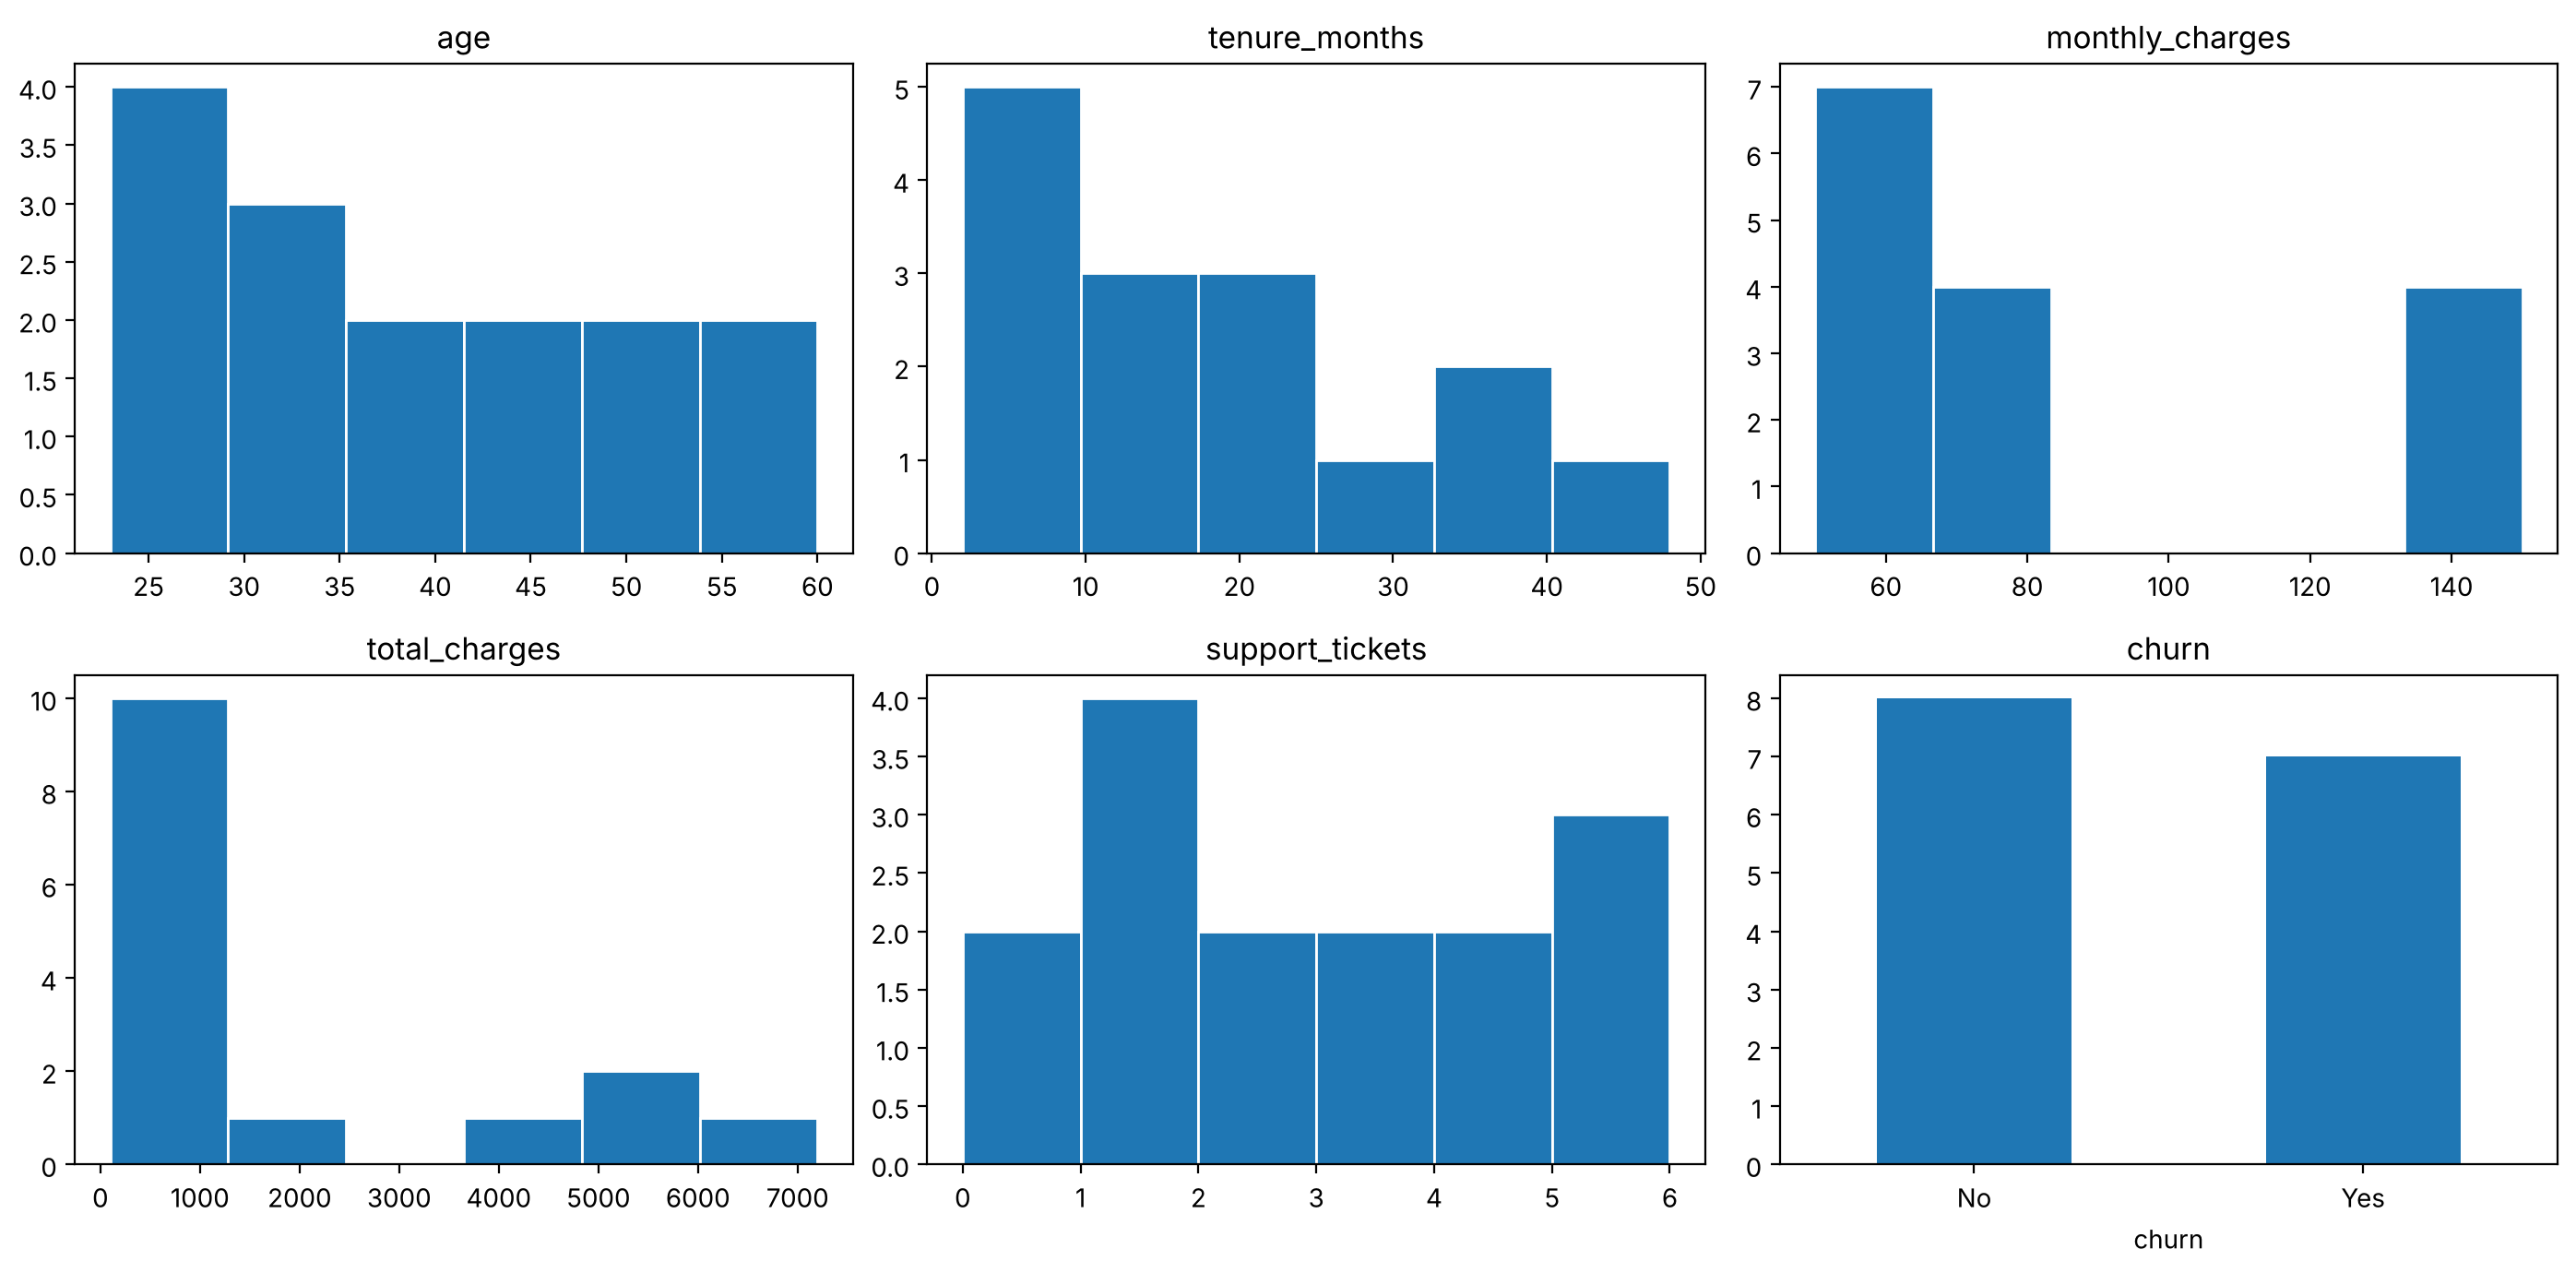

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for a, c in zip(ax.flat, ['age','tenure_months','monthly_charges','total_charges','support_tickets']):
    a.hist(df[c], bins=6, edgecolor='white'); a.set_title(c)
df['churn'].value_counts().plot.bar(ax=ax.flat[5], title='churn', rot=0)
plt.tight_layout(); plt.show()

## 7. Churn by segment

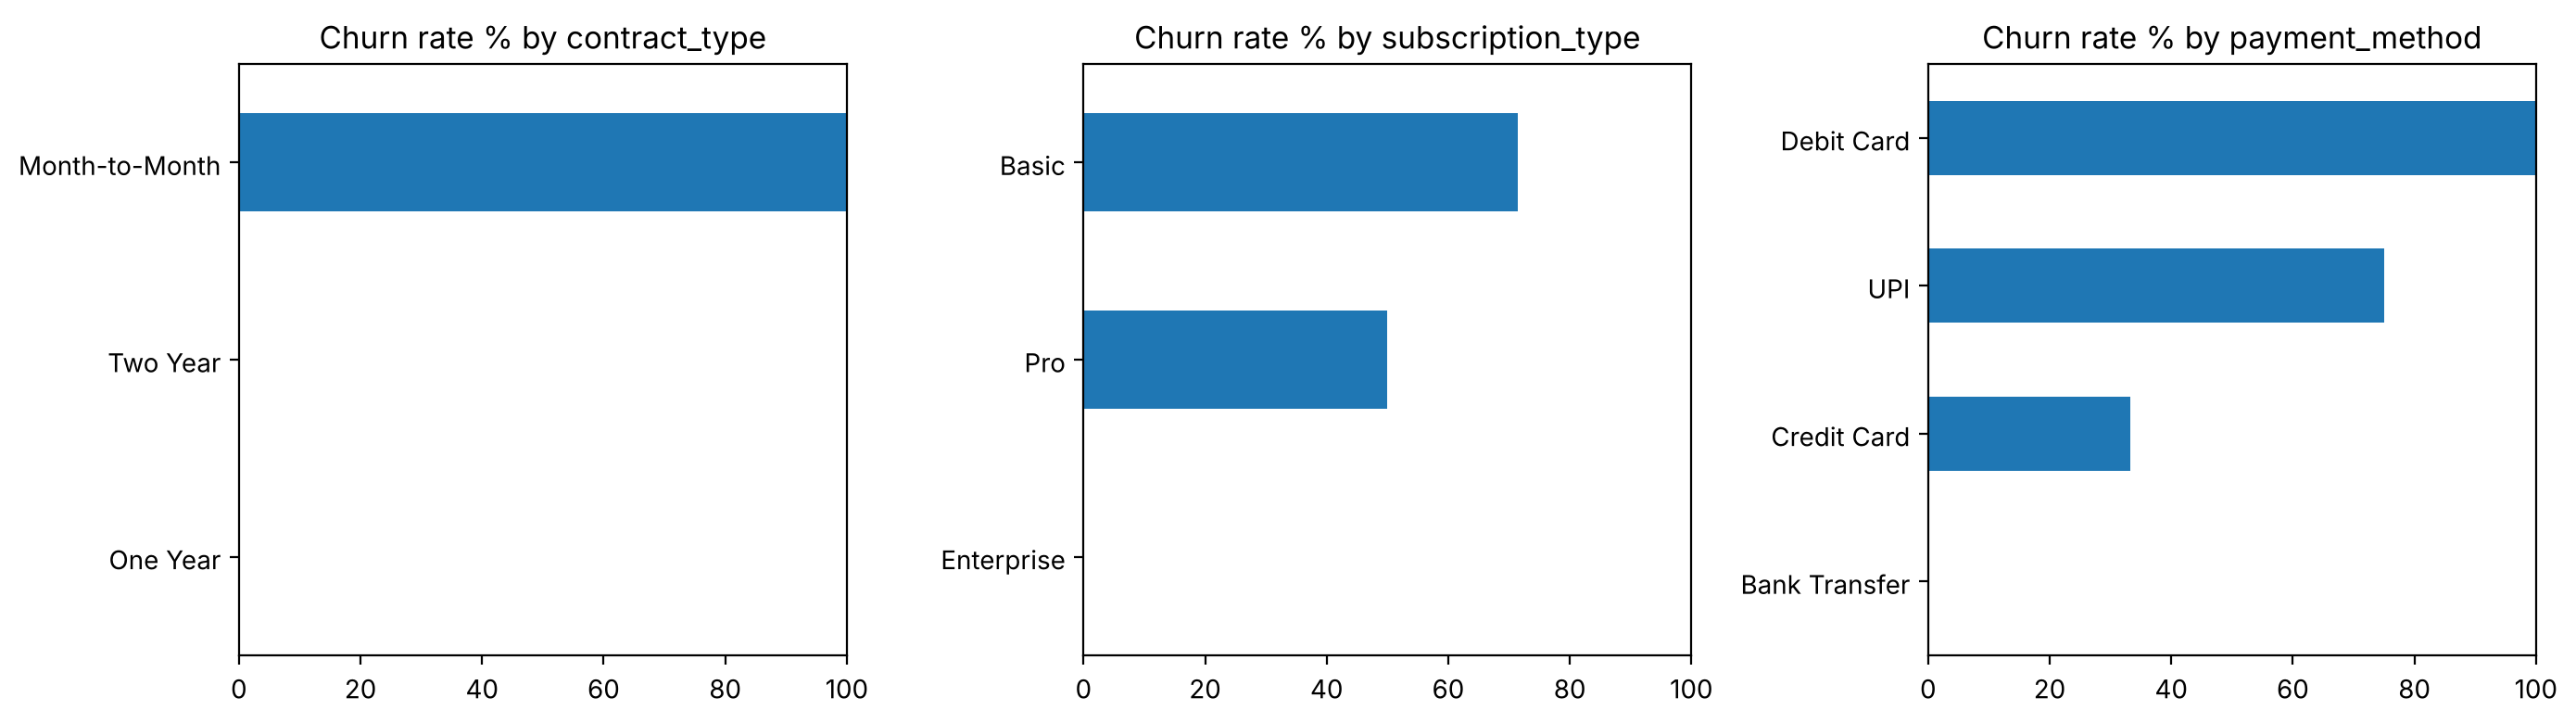

churn,No,Yes
contract_type,,
Month-to-Month,0,7
One Year,4,0
Two Year,4,0


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, c in zip(ax, ['contract_type', 'subscription_type', 'payment_method']):
    (df.groupby(c, observed=True)['churn_flag'].mean() * 100).sort_values().plot.barh(ax=a, title=f'Churn rate % by {c}')
    a.set_xlim(0, 100); a.set_ylabel('')
plt.tight_layout(); plt.show()

pd.crosstab(df['contract_type'], df['churn'])

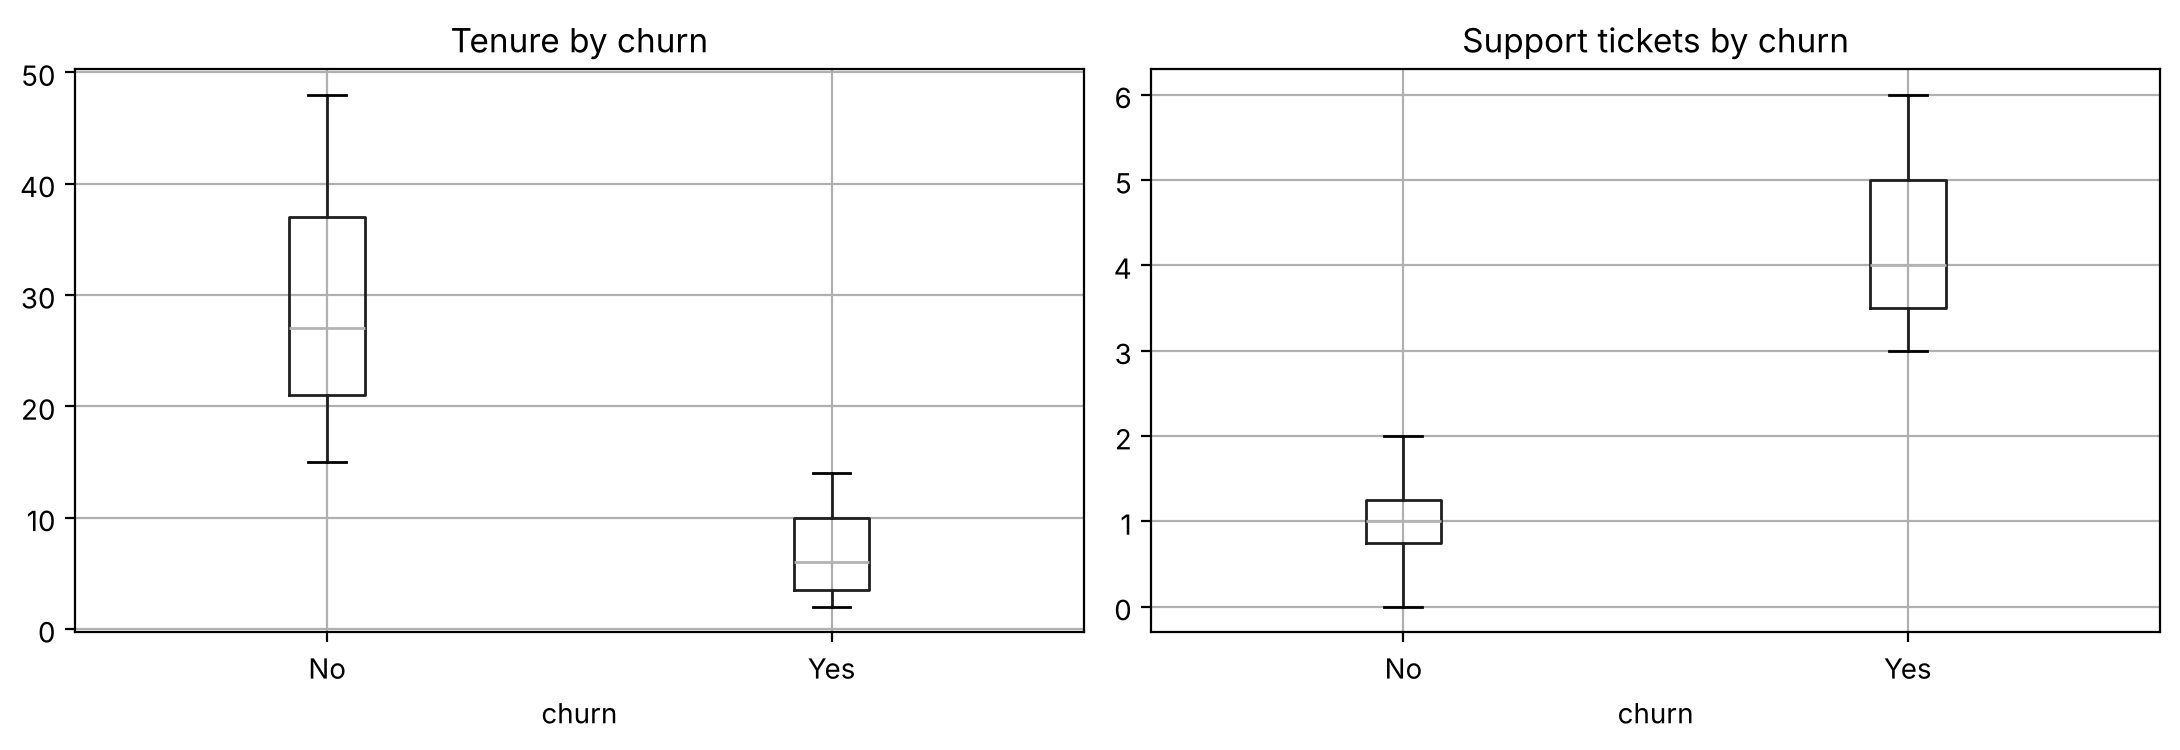

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.boxplot(column='tenure_months', by='churn', ax=ax[0]); ax[0].set_title('Tenure by churn')
df.boxplot(column='support_tickets', by='churn', ax=ax[1]); ax[1].set_title('Support tickets by churn')
plt.suptitle(''); plt.tight_layout(); plt.show()

## 8. Data-quality summary

**Issues found**
- 15 rows, 11 columns. No missing values, no duplicate rows, no duplicate customer IDs.
- No IQR outliers in any numeric column. The widest spread is `total_charges`, which is driven by tenure and plan price, not by errors.

**Decisions and assumptions**
- Nothing was dropped or imputed, because every validation check passed.
- `TotalCharges` equals `MonthlyCharges x TenureMonths` for all rows, so it is treated as a derived column and kept.
- Column names were converted to snake_case, text was trimmed, and categorical columns were typed as `category`.
- Added `churn_flag` (1 = Yes, 0 = No) for analysis.
- Assumption: charges are in a single currency.

**Validation**
- Post-clean assertions confirm unique IDs, no nulls, and the same row count as the raw file.

**Initial patterns** (descriptive only; n = 15 is too small to draw statistical conclusions)
- Overall churn rate is 46.7% (7 of 15).
- **Contract type:** all 7 Month-to-Month customers churned; none of the 8 One Year or Two Year customers did.
- **Tenure:** churned customers averaged 7 months vs about 29 for retained customers.
- **Support tickets:** churned customers averaged about 4.3 tickets vs 1.0.
- **Plan:** 5 of 7 Basic customers churned; 0 of 4 Enterprise customers did.
- **Age and price:** churners are younger (about 30 vs 47) and on cheaper plans (about 59 vs 107 per month). Plan and contract overlap heavily, so these may be the same signal.

**Limitations and next steps**
- Small synthetic sample, so patterns are illustrative.
- Contract, tenure, and plan are strongly linked; a larger dataset would be needed to separate their effects.
- Suggested action: target Month-to-Month customers with 3+ support tickets for retention offers.